# WRF vertical cross sections

In [14]:
import gc
import glob
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from netCDF4 import Dataset
from scipy.ndimage import map_coordinates
from scipy.spatial import cKDTree
import pyart
# For optional simulated reflectivity calculated on the cropped subdomain.
from wrf import dbz as wrf_dbz, vertcross, CoordPair

# Display process memory (RSS), useful for diagnosing RAM spikes.
def show_memory(label=""):
    try:
        import psutil
        gb = psutil.Process(os.getpid()).memory_info().rss / 2**30
        print(f"{label}: process memory = {gb:.2f} GiB")
    except ImportError:
        pass



## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly
## supported by the U.S. Department of Energy as part of the Atmospheric
## Radiation Measurement (ARM) Climate Research Facility, an Office of
## Science user facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



In [2]:
data_dir = Path("/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1/")
plotsdir = Path("/glade/u/home/athornton/wrf_visualization/cold_pool_data/")
plotsdir = Path("./")
datafiles = sorted(str(p) for p in data_dir.glob("wrfout_d03*"))
print(f"Found {len(datafiles)} files")
assert datafiles, f"No WRF files found under {data_dir}"
plotsdir.mkdir(parents=True, exist_ok=True)

Found 85 files


In [3]:
# Read only 2D geographic coordinates (not 3D pressure!) from one reference file.
with Dataset(datafiles[0]) as nc:
    lats_np = np.asarray(nc.variables["XLAT"][0], dtype=np.float32)
    lons_np = np.asarray(nc.variables["XLONG"][0], dtype=np.float32)

print("Grid size (y, x):", lats_np.shape)


Grid size (y, x): (2643, 2490)


In [17]:
# Endpoints, in degrees north/east.
lat_min, lat_max = 8.5, 10.25
lon_min, lon_max = -16.5, -10.75

# Use a physical pressure grid, shared across all sections.
PRESSURE_LEVELS_HPA = np.arange(100., 1001., 10., dtype=np.float32)

# Margin around transect; NOT a full-domain read.
CROP_MARGIN_GRIDPOINTS = 8

# Cross-section sampling resolution on the native horizontal grid.
POINTS_PER_GRID_CELL = 1.0

# Approximate horizontal metric for latitude/longitude near the transect.
def _closest_grid_point(lat2d, lon2d, latitude, longitude):
    coslat = np.cos(np.deg2rad(latitude))
    pts = np.column_stack((lat2d.ravel(), lon2d.ravel() * coslat))
    _, idx = cKDTree(pts).query((latitude, longitude * coslat))
    return np.unravel_index(idx, lat2d.shape)

# 2D WRF coordinates may not be separable into lat[:,0] and lon[0,:].
START_YX = _closest_grid_point(lats_np, lons_np, lat_min, lon_min)
END_YX = _closest_grid_point(lats_np, lons_np, lat_max, lon_max)
print('Nearest transect endpoints (y,x):', START_YX, END_YX)


Nearest transect endpoints (y,x): (np.int64(839), np.int64(1097)) (np.int64(1030), np.int64(1715))


In [18]:
# Interpolation behavior for reflectivity. Set False to match earlier notebook.
REFLECTIVITY_LINEAR_Z = True


def get_data(index, lon_box=(-17.5, -16.5), lat_box=None,
             block_points=24, margin=3):
    """Memory-limited WRF cross sections computed with wrf.vertcross.

    Each segment crops to a small rectangular WRF subdomain; x,y endpoints
    are expressed in the LOCAL cropped grid coordinate system. This avoids
    mismatches between full-domain wrfin coordinates and cropped arrays.
    Input variables remain in native mass-grid coordinates; u/v/w destaggered.
    """
    if lat_box is None:
        lat_box = (lat_min, lat_max)
    if not 0 <= index < len(datafiles):
        raise IndexError(f'Invalid WRF file index: {index}')
    if block_points < 2:
        raise ValueError('block_points must be >= 2')
    levels = np.asarray(PRESSURE_LEVELS_HPA, dtype=np.float64)

    with Dataset(datafiles[index]) as nc:
        lat2 = np.asarray(nc.variables['XLAT'][0], dtype=np.float32)
        lon2 = np.asarray(nc.variables['XLONG'][0], dtype=np.float32)
        y0, x0 = _closest_grid_point(lat2, lon2, lat_min, lon_min)
        y1, x1 = _closest_grid_point(lat2, lon2, lat_max, lon_max)
        npts = max(2, int(np.ceil(np.hypot(y1-y0, x1-x0)
                                      * POINTS_PER_GRID_CELL)) + 1)
        yline = np.linspace(y0, y1, npts)
        xline = np.linspace(x0, x1, npts)
        ny, nx = lat2.shape
        nlev = nc.dimensions['bottom_top'].size

        def read(name, sy, sx):
            return np.asarray(nc.variables[name][0, :, sy, sx], dtype=np.float32)

        # Reference theta profile: identical algorithm to companion notebook.
        latlo, lathi = sorted(lat_box)
        lonlo, lonhi = sorted(lon_box)
        mask = ((lat2 >= latlo) & (lat2 <= lathi) &
                (lon2 >= lonlo) & (lon2 <= lonhi))
        by, bx = np.where(mask)
        if by.size == 0:
            raise ValueError('Ambient theta box contains no grid cells')
        sy = slice(int(by.min()), int(by.max()) + 1)
        sx = slice(int(bx.min()), int(bx.max()) + 1)
        box = read('T', sy, sx)
        theta_base = (box[:, mask[sy, sx]].mean(axis=1, dtype=np.float64)
                      .astype(np.float32) + np.float32(300.0))
        del box

        def vc(field, pressure, start, end):
            # Use cropped-grid x/y coordinates. No wrfin needed.
            result = vertcross(
                field, pressure, levels=levels,
                start_point=start, end_point=end,
                latlon=False, meta=False,
            )
            # wrf.vertcross returns a masked array for out-of-range levels.
            return np.ma.filled(np.ma.asarray(result), np.nan).astype(np.float32)

        pieces = {k: [] for k in ('w', 'theta', 'u', 'v', 'dbz')}
        latpieces, lonpieces = [], []
        # Adjacent segments share their endpoints. Remove the overlapping
        # first column of all but the first segment before joining.
        for a in range(0, npts - 1, block_points - 1):
            b = min(a + block_points, npts)
            yy, xx = yline[a:b], xline[a:b]
            ys = max(0, int(np.floor(yy.min())) - margin)
            ye = min(ny, int(np.ceil(yy.max())) + margin + 1)
            xs = max(0, int(np.floor(xx.min())) - margin)
            xe = min(nx, int(np.ceil(xx.max())) + margin + 1)
            Y, X = slice(ys, ye), slice(xs, xe)
            start = CoordPair(x=float(xx[0]-xs), y=float(yy[0]-ys))
            end = CoordPair(x=float(xx[-1]-xs), y=float(yy[-1]-ys))

            p_pa = read('P', Y, X)
            p_pa += read('PB', Y, X)
            p_hpa = p_pa / np.float32(100.0)

            theta = read('T', Y, X) + np.float32(300.0)
            theta -= theta_base[:, None, None]
            U = read('U', Y, slice(xs, xe+1))
            u = np.float32(0.5) * (U[..., :-1] + U[..., 1:])
            del U
            V = read('V', slice(ys, ye+1), X)
            v = np.float32(0.5) * (V[:, :-1, :] + V[:, 1:, :])
            del V
            W = read('W', Y, X)
            w = np.float32(0.5) * (W[:-1, :, :] + W[1:, :, :])
            del W

            fields = {'theta': theta, 'u': u, 'v': v, 'w': w}
            if 'REFL_10CM' in nc.variables:
                dbz = read('REFL_10CM', Y, X)
            else:
                if not {'QVAPOR', 'QRAIN'}.issubset(nc.variables):
                    raise KeyError('Reflectivity requires REFL_10CM or QVAPOR and QRAIN')
                qv = read('QVAPOR', Y, X)
                qr = read('QRAIN', Y, X)
                qs = (read('QSNOW', Y, X) if 'QSNOW' in nc.variables
                      else np.zeros_like(qr))
                qg = (read('QGRAUP', Y, X) if 'QGRAUP' in nc.variables
                      else np.zeros_like(qr))
                theta_abs = read('T', Y, X) + np.float32(300.)
                tkel = theta_abs * (p_pa / np.float32(1e5)) ** np.float32(.2854)
                dbz = np.asarray(wrf_dbz(p_pa, tkel, qv, qr, qs, qg,
                                         meta=False), dtype=np.float32)
                del qv, qr, qs, qg, theta_abs, tkel
            # WRF example: interpolate linear reflectivity, then convert to dBZ.
            if REFLECTIVITY_LINEAR_Z:
                dbz = np.power(np.float32(10.0), dbz / np.float32(10.0))
            fields['dbz'] = dbz
            segment_results = {key: vc(arr, p_hpa, start, end)
                               for key, arr in fields.items()}
            if REFLECTIVITY_LINEAR_Z:
                z_section = segment_results['dbz']
                with np.errstate(divide='ignore', invalid='ignore'):
                    segment_results['dbz'] = 10.0 * np.log10(z_section)
            # Obtain horizontal coordinates at the exact horizontal samples
            # used by vertcross
            nseg = segment_results['w'].shape[1]
            ysamp = np.linspace(yy[0], yy[-1], nseg)
            xsamp = np.linspace(xx[0], xx[-1], nseg)
            from scipy.ndimage import map_coordinates
            xy = np.stack((ysamp, xsamp))
            latseg = map_coordinates(lat2, xy, order=1, mode='nearest', prefilter=False)
            lonseg = map_coordinates(lon2, xy, order=1, mode='nearest', prefilter=False)
            keep = slice(None) if a == 0 else slice(1, None)
            for key in pieces:
                pieces[key].append(segment_results[key][:, keep])
            latpieces.append(latseg[keep])
            lonpieces.append(lonseg[keep])
            del fields, segment_results, p_pa, p_hpa, dbz, u, v, w, theta

        output = {k: np.concatenate(v, axis=1) for k, v in pieces.items()}
        latline = np.concatenate(latpieces)
        lonline = np.concatenate(lonpieces)
        latrad = np.deg2rad(latline.astype(np.float64))
        lonrad = np.unwrap(np.deg2rad(lonline.astype(np.float64)))
        east = 6371.0 * np.cos(.5*(latrad[1:]+latrad[:-1])) * np.diff(lonrad)
        north = 6371.0 * np.diff(latrad)
        dist = np.r_[0.0, np.cumsum(np.hypot(east, north))]
        e_dir = np.gradient(np.r_[0.0, np.cumsum(east)])
        n_dir = np.gradient(np.r_[0.0, np.cumsum(north)])
        norm = np.hypot(e_dir, n_dir)
        if np.any(norm <= 0):
            raise ValueError('Invalid cross-section path')
        east_unit = (e_dir / norm).astype(np.float32)
        north_unit = (n_dir / norm).astype(np.float32)
        raw_time = nc.variables['Times'][0]
        timestr = (b''.join(raw_time).decode('ascii')
                   if raw_time.dtype.kind == 'S'
                   else ''.join(raw_time.astype(str)))
        filetime = timestr[:16].replace('T', '_').replace(' ', '_')
    gc.collect()
    show_memory(f'After vertcross get_data({index})')
    return (output['w'], output['theta'], output['u'], output['v'],
            output['dbz'], filetime, dist, levels, east_unit, north_unit)


In [19]:
def get_proj(u_cross, v_cross, east_unit, north_unit):
    """Return horizontal wind along the physical transect (m/s).
    """
    return u_cross * east_unit[None, :] + v_cross * north_unit[None, :]


In [20]:
titles_theta = ['(a)', '(b)', '(c)', '(d)']
titles_dbz = ['(e)', '(f)', '(g)', '(h)']


In [21]:
indices = [36,39,48,53]
assert max(indices) < len(datafiles), f'Need file index {max(indices)} but found only {len(datafiles)} files'


After vertcross get_data(36): process memory = 0.77 GiB
After vertcross get_data(39): process memory = 0.77 GiB
After vertcross get_data(48): process memory = 0.79 GiB
After vertcross get_data(53): process memory = 0.79 GiB


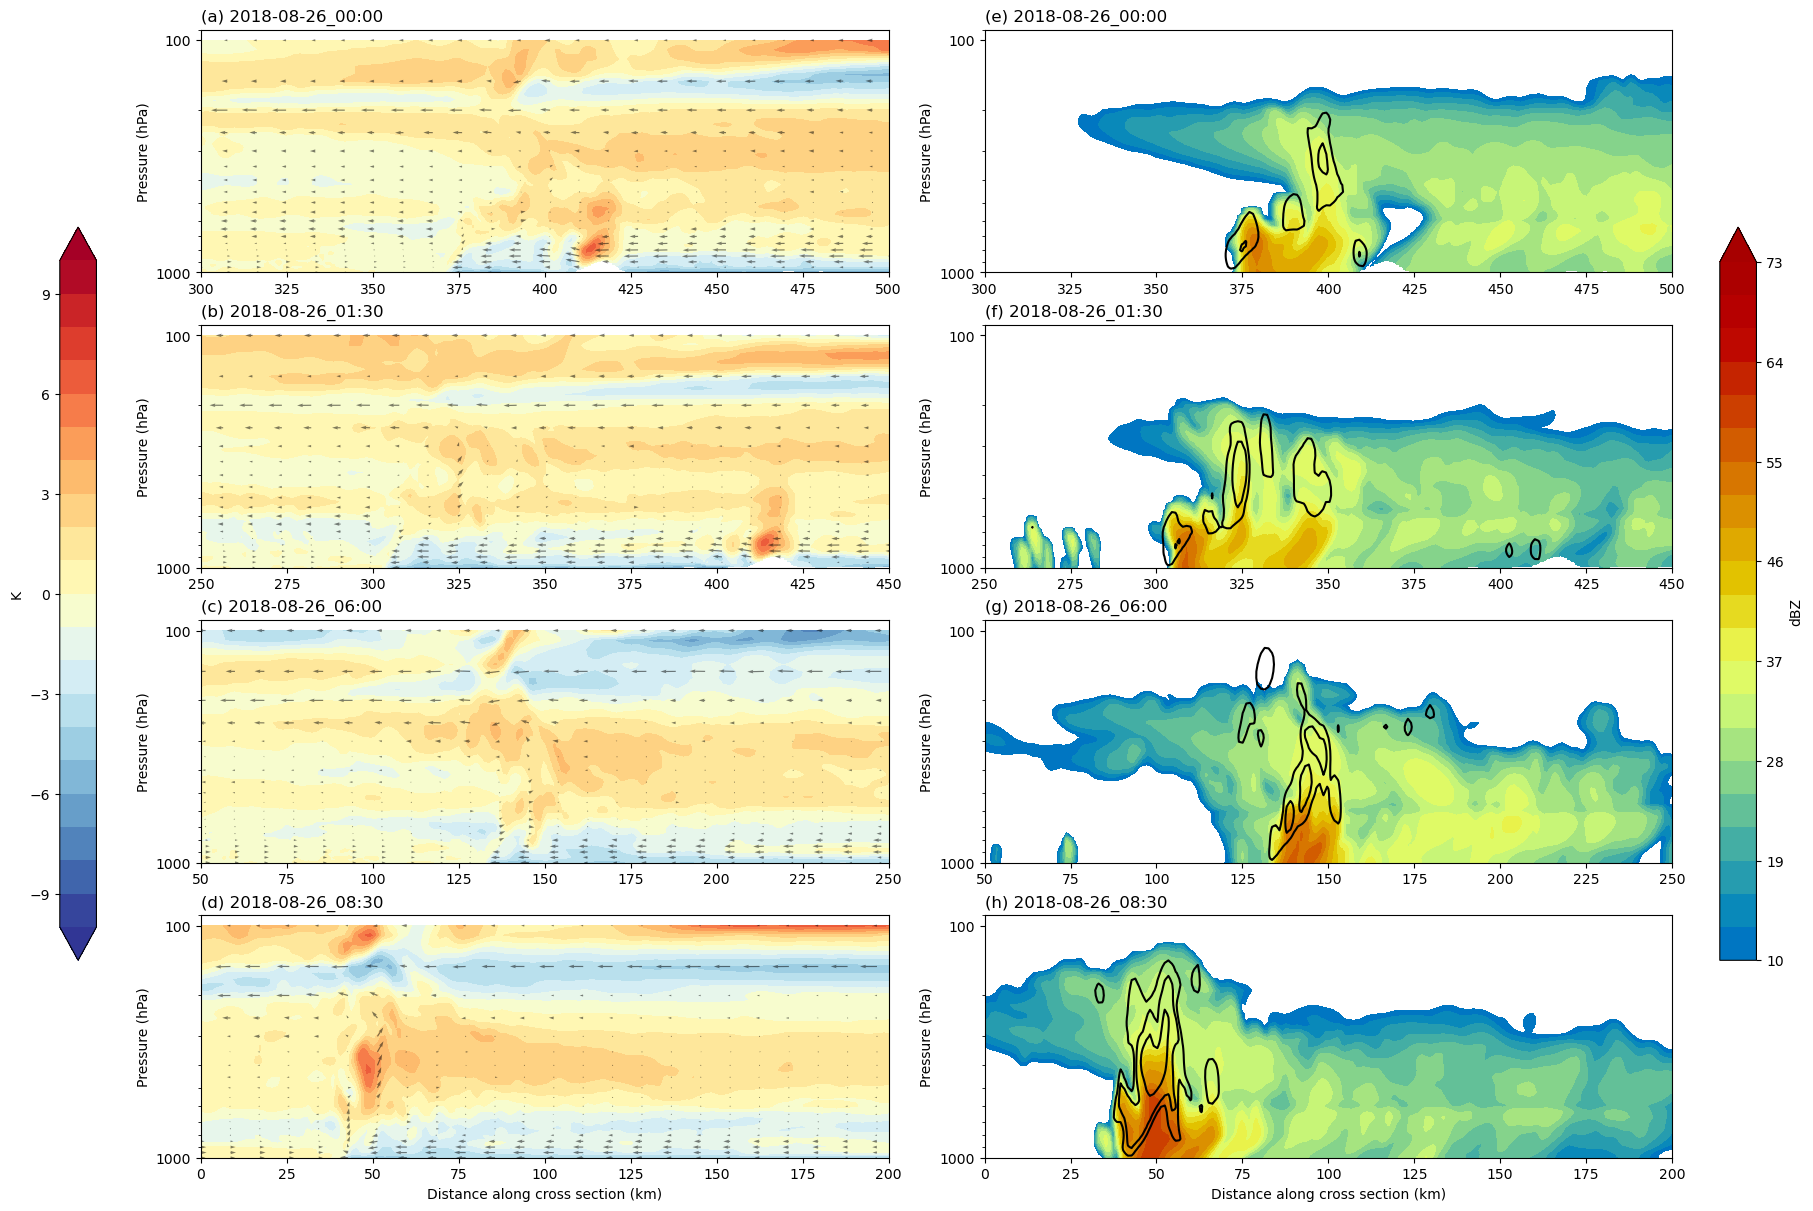

In [22]:
plt.rcParams['savefig.dpi'] = 155
fig, ax = plt.subplots(len(indices), 2, figsize=(18, 12), constrained_layout=True)

for i, file_index in enumerate(indices):
    # Ambient theta reference longitude box shifts with time (as original).
    lon_max2 = -16.5 - 0.1 * i
    lon_min2 = lon_max2 - 1.0

    (w_cross, theta_cross, u_cross, v_cross, ref_cross,
     filetime, dist, pressure, east_unit, north_unit) = get_data(
         file_index, lon_box=(lon_min2, lon_max2), lat_box=(lat_min, lat_max))

    along_wind = get_proj(u_cross, v_cross, east_unit, north_unit)

    cf = ax[i, 0].contourf(dist, pressure, theta_cross,
                           levels=np.arange(-10, 11), cmap='RdYlBu_r', extend='both')
    cf2 = ax[i, 1].contourf(dist, pressure, ref_cross,
                            levels=np.arange(10, 76, 3), cmap='HomeyerRainbow', extend='max')
    ax[i, 1].contour(dist, pressure, w_cross,
                     levels=[2, 6, 15], colors='black', linewidths=1.5)

    # Correct physical velocity component along the transect.
    js = slice(None, None, 8)
    ks = slice(None, None, 5)
    ax[i, 0].quiver(dist[js], pressure[ks], along_wind[ks, js], w_cross[ks, js],
                    width=0.0017, scale=1200, color='black', alpha=0.5)

    for j in range(2):
        a = ax[i, j]
        a.set_yscale('log')
        a.set_ylim(1000, 90)
        a.yaxis.set_major_formatter(ScalarFormatter())
        a.set_ylabel('Pressure (hPa)')
        # The original x limits were approximate gridpoint distances.
        # Here x is actual distance in km. Set limits if desired:
        #a.set_xlim(350 - 25*i, 550 - 25*i)
        if i == 0:
            a.set_xlim(300, 500)
        if i == 1:
            a.set_xlim(250, 450)
        if i == 2:
            a.set_xlim(50, 250)        
        if i == 3:
            a.set_xlim(0, 200)
            
    ax[i, 0].set_title(f'{titles_theta[i]} {filetime}', loc='left')
    ax[i, 1].set_title(f'{titles_dbz[i]} {filetime}', loc='left')

    # Release cross-section arrays BEFORE processing another WRF file.
    del w_cross, theta_cross, u_cross, v_cross, ref_cross, along_wind
    gc.collect()

ax[-1, 0].set_xlabel('Distance along cross section (km)')
ax[-1, 1].set_xlabel('Distance along cross section (km)')
fig.colorbar(cf, ax=ax[:, 0], location='left', shrink=0.65, label='K')
fig.colorbar(cf2, ax=ax[:, 1], location='right', shrink=0.65, label='dBZ')
fig.savefig(plotsdir / 'X_section_thetaSOUTH.png', bbox_inches='tight')
plt.show()
plt.close(fig)


In [13]:
pressure

array([ 100.,  110.,  120.,  130.,  140.,  150.,  160.,  170.,  180.,
        190.,  200.,  210.,  220.,  230.,  240.,  250.,  260.,  270.,
        280.,  290.,  300.,  310.,  320.,  330.,  340.,  350.,  360.,
        370.,  380.,  390.,  400.,  410.,  420.,  430.,  440.,  450.,
        460.,  470.,  480.,  490.,  500.,  510.,  520.,  530.,  540.,
        550.,  560.,  570.,  580.,  590.,  600.,  610.,  620.,  630.,
        640.,  650.,  660.,  670.,  680.,  690.,  700.,  710.,  720.,
        730.,  740.,  750.,  760.,  770.,  780.,  790.,  800.,  810.,
        820.,  830.,  840.,  850.,  860.,  870.,  880.,  890.,  900.,
        910.,  920.,  930.,  940.,  950.,  960.,  970.,  980.,  990.,
       1000.])